# Projet Big Data — NBA : déroulé d'un match, choix de tir et stratégies de fin de match

**Pipeline** : `data/archive/csv/*.csv` (Kaggle `wyattowalsh/basketball`) → **Spark** (préparation + analyses distribuées) → **HDFS** (parquet persisté) → agrégats → **MongoDB** (couche de serving) → visualisations.

Le fichier `play_by_play.csv` (~2,2 Go, ~13 M d'événements) décrit chaque action de chaque match depuis 1996-97 ; `game.csv` couvre tous les matchs depuis 1946. On se limite à la **saison régulière** pour la comparabilité.

## 1. Ingestion & préparation

Lecture des CSV, enrichissement du play-by-play (temps de jeu écoulé, côté de l'équipe, points marqués par action, type de tir, marge courante) puis persistance en **parquet sur HDFS** — c'est la couche « données traitées » de l'architecture.

In [1]:
from pyspark.sql import SparkSession, functions as F, Window
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns, pymongo, json

spark = SparkSession.builder.appName("nba-analyse").getOrCreate()
CSV = "/work/data/archive/csv"
RESULTATS = {}  # agregats -> MongoDB a la fin

pbp_raw = spark.read.option("header", "true").csv(f"{CSV}/play_by_play.csv")
game = spark.read.option("header", "true").csv(f"{CSV}/game.csv")

# legende des types d'evenement (eventmsgtype, API NBA)
# 1=FG marque 2=FG manque 3=lancer 4=rebond 5=perte 6=faute 7=violation
# 8=remplacement 9=temps mort 10=entre-deux 11=expulsion 12/13=debut/fin periode
pbp_raw.groupBy("eventmsgtype").count().orderBy("eventmsgtype").show(20)

Matplotlib created a temporary cache directory at /tmp/matplotlib-vctbzdat because the default path (/tmp/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


09:46:18 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+------------+-------+
|eventmsgtype|  count|
+------------+-------+
|           1|2242357|
|          10|  52099|
|          11|   1984|
|          12| 121226|
|          13| 121424|
|          18|  28193|
|           2|2699376|
|           3|1442567|
|           4|3049623|
|           5| 868202|
|           6|1305746|
|           7|  53184|
|           8|1226332|
|           9| 380586|
+------------+-------+



In [2]:
# preparation du play-by-play
w = Window.partitionBy("game_id").orderBy("eventnum").rowsBetween(Window.unboundedPreceding, 0)

pbp = (pbp_raw.select("game_id", "eventnum", "eventmsgtype", "period",
                      "pctimestring", "score",
                      F.col("homedescription").alias("hd"), F.col("visitordescription").alias("vd"),
                      "player1_name", "player1_team_abbreviation",
                      F.col("player2_name").alias("passeur"))
    .withColumn("eventnum", F.col("eventnum").cast("int"))
    .withColumn("eventmsgtype", F.col("eventmsgtype").cast("int"))
    .withColumn("period", F.col("period").cast("int"))
    .withColumn("rest", F.split("pctimestring", ":").getItem(0).cast("int") * 60
                      + F.split("pctimestring", ":").getItem(1).cast("int"))
    .withColumn("sec", F.when(F.col("period") <= 4, (F.col("period") - 1) * 720 + 720 - F.col("rest"))
                       .otherwise(2880 + (F.col("period") - 5) * 300 + 300 - F.col("rest")))
    .withColumn("side", F.when(F.col("hd").isNotNull(), "H")
                        .when(F.col("vd").isNotNull(), "A").otherwise("N"))
    .withColumn("descr", F.coalesce("hd", "vd"))
    .withColumn("pts", F.when(F.col("eventmsgtype") == 1,
                              F.when(F.col("descr").contains("3PT"), 3).otherwise(2))
                       .when((F.col("eventmsgtype") == 3) & (~F.col("descr").contains("MISS")), 1)
                       .otherwise(0))
    .withColumn("tir", F.when(F.col("descr").contains("3PT"), "3 points")
                       .when(F.col("descr").rlike("Dunk|Layup|Tip|Alley Oop|Finger Roll"), "proche cercle")
                       .when(F.col("eventmsgtype").isin(1, 2), "mi-distance"))
    # score "ext - dom" recopie vers le bas -> marge domicile a chaque evenement
    .withColumn("score_f", F.last(F.when(F.length("score") > 0, F.col("score")), True).over(w))
    .withColumn("marge_dom", F.split("score_f", " - ").getItem(1).cast("int")
                           - F.split("score_f", " - ").getItem(0).cast("int")))

# saison reguliere vs playoffs + annee (season_id 21946 -> 1946)
# dropDuplicates : les matchs All-Star sont listes 2x dans game.csv
g = (game.select("game_id", "season_id", "game_date", "season_type", "wl_home",
                 "team_abbreviation_home", "team_abbreviation_away")
        .dropDuplicates(["game_id"])
        .withColumn("annee", F.col("season_id").cast("int") - 20000))

pbp = pbp.join(g, "game_id")
pbp.write.mode("overwrite").parquet("hdfs://namenode:9000/nba/pbp")

# on relit le parquet : colonnes prunees a chaque analyse, pas de cache (trop volumineux)
pbp = spark.read.parquet("hdfs://namenode:9000/nba/pbp")
rs = pbp.filter(F.col("season_type") == "Regular Season")
print("evenements:", pbp.count())
print("evenements saison reguliere:", rs.count())

09:46:54 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


evenements: 13592899


evenements saison reguliere: 12466438


## 2. Le déroulé d'un match

Répartition des actions minute par minute, puis comparaison des rythmes par quart-temps.

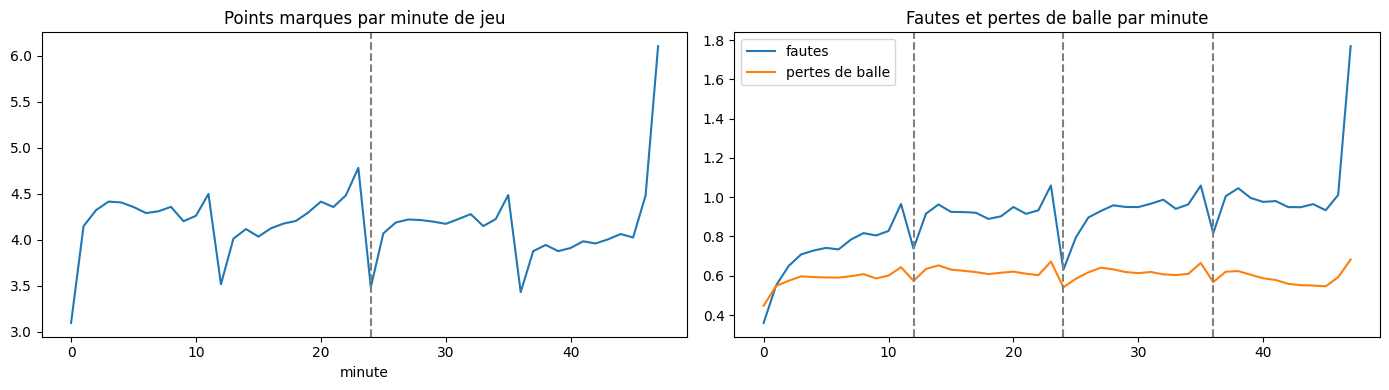

In [3]:
# actions par minute de jeu (moyenne par match)
n_matchs = rs.select("game_id").distinct().count()
par_min = (rs.filter(F.col("sec") < 2880).withColumn("minute", F.floor(F.col("sec") / 60))
    .groupBy("minute")
    .agg(F.count(F.when(F.col("eventmsgtype") == 6, 1)).alias("fautes"),
         F.count(F.when(F.col("eventmsgtype") == 5, 1)).alias("pertes"),
         F.sum("pts").alias("pts"))
    .orderBy("minute").toPandas())
par_min[["fautes", "pertes", "pts"]] /= n_matchs
RESULTATS["actions_minute"] = par_min

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(par_min.minute, par_min.pts); ax[0].set_title("Points marques par minute de jeu")
ax[0].set_xlabel("minute"); ax[0].axvline(24, ls="--", c="grey")
ax[1].plot(par_min.minute, par_min.fautes, label="fautes")
ax[1].plot(par_min.minute, par_min.pertes, label="pertes de balle")
ax[1].set_title("Fautes et pertes de balle par minute"); ax[1].legend()
for x in (12, 24, 36): ax[1].axvline(x, ls="--", c="grey")
plt.tight_layout(); plt.savefig("/work/resultats/02_actions_minute.png"); plt.show()

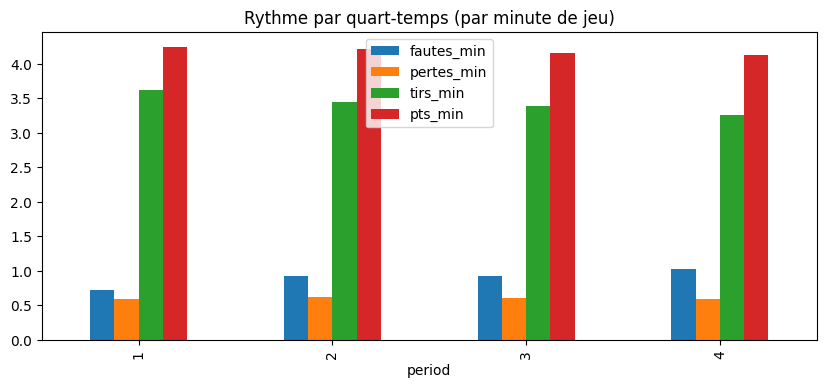

In [4]:
# comparaison des quart-temps : rythme (par minute de jeu)
par_qt = (rs.filter(F.col("period") <= 4).groupBy("period")
    .agg((F.count(F.when(F.col("eventmsgtype") == 6, 1)) / (n_matchs * 12)).alias("fautes_min"),
         (F.count(F.when(F.col("eventmsgtype") == 5, 1)) / (n_matchs * 12)).alias("pertes_min"),
         (F.count(F.when(F.col("eventmsgtype").isin(1, 2), 1)) / (n_matchs * 12)).alias("tirs_min"),
         (F.sum("pts") / (n_matchs * 12)).alias("pts_min"))
    .orderBy("period").toPandas())
RESULTATS["par_quart_temps"] = par_qt

par_qt.plot(x="period", kind="bar", figsize=(10, 4),
            title="Rythme par quart-temps (par minute de jeu)")
plt.savefig("/work/resultats/02_quart_temps.png"); plt.show()

## 3. Les choix de tir

Part des tirs à 3 points / proche cercle / mi-distance selon les quart-temps et les saisons, et jeu collectif (passe décisive) contre isolation.

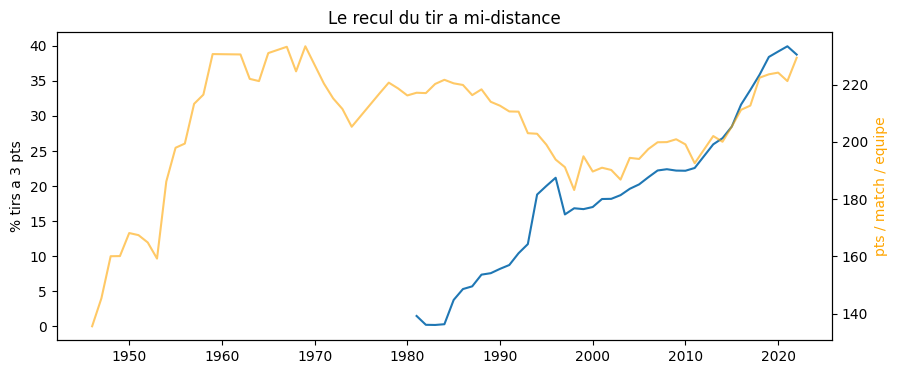

In [5]:
# evolution historique : part des tirs a 3 pts et rythme (depuis 1946, via game.csv)
saisons = (game.filter(F.col("season_type") == "Regular Season")
    .withColumn("annee", F.col("season_id").cast("int") - 20000)
    .withColumn("t3", F.col("fg3a_home").cast("double") + F.col("fg3a_away").cast("double"))
    .withColumn("tt", F.col("fga_home").cast("double") + F.col("fga_away").cast("double"))
    .groupBy("annee")
    .agg((F.sum("t3") / F.sum("tt")).alias("part_3pts"),
         (F.avg(F.col("pts_home").cast("double")) + F.avg(F.col("pts_away").cast("double"))).alias("pts_match"))
    .orderBy("annee").toPandas())
RESULTATS["tirs_par_saison"] = saisons

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(saisons.annee, saisons.part_3pts * 100); ax.set_ylabel("% tirs a 3 pts")
ax2 = ax.twinx(); ax2.plot(saisons.annee, saisons.pts_match, c="orange", alpha=.6)
ax2.set_ylabel("pts / match / equipe", c="orange"); ax.set_title("Le recul du tir a mi-distance")
plt.savefig("/work/resultats/03_evolution_3pts.png"); plt.show()

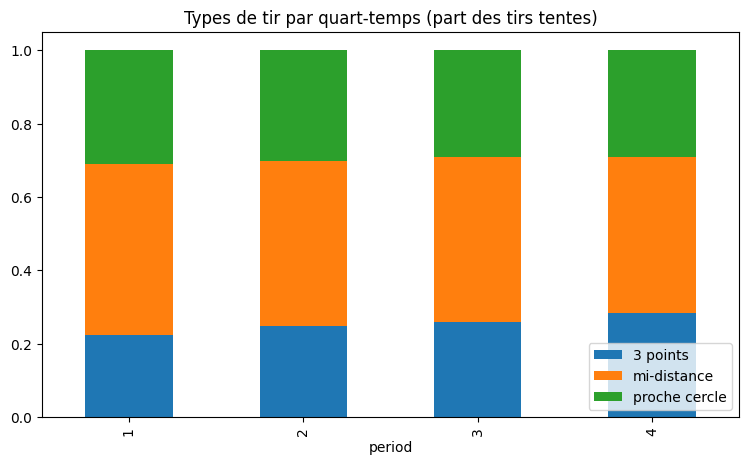

In [6]:
# type de tir par quart-temps (play-by-play, tirs tentes)
tirs_qt = (rs.filter(F.col("tir").isNotNull() & (F.col("period") <= 4))
    .groupBy("period", "tir").count().toPandas()
    .pivot(index="period", columns="tir", values="count").fillna(0))
tirs_qt = tirs_qt.div(tirs_qt.sum(axis=1), axis=0)
RESULTATS["tirs_par_quart"] = tirs_qt.reset_index()

tirs_qt.plot(kind="bar", stacked=True, figsize=(9, 5),
             title="Types de tir par quart-temps (part des tirs tentes)")
plt.legend(loc="lower right"); plt.savefig("/work/resultats/03_tirs_quart.png"); plt.show()

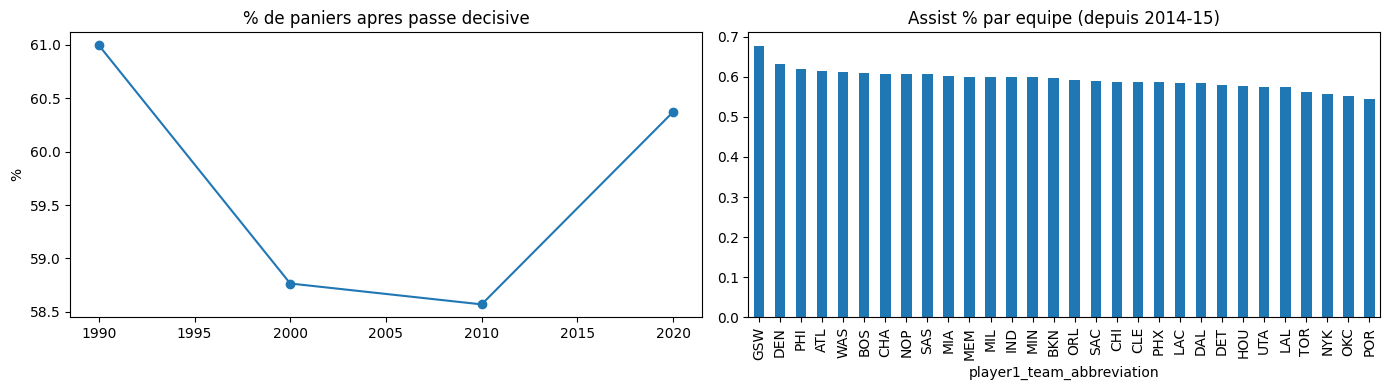

In [7]:
# jeu collectif vs isolation : part des paniers marques sur passe decisive
assist = (rs.filter(F.col("eventmsgtype") == 1)
    .withColumn("decennie", (F.col("annee") / 10).cast("int") * 10)
    .groupBy("decennie")
    .agg(F.mean(F.col("passeur").isNotNull().cast("int")).alias("part_assistee"))
    .orderBy("decennie").toPandas())
RESULTATS["assist_decennie"] = assist

par_equipe = (rs.filter((F.col("eventmsgtype") == 1) & (F.col("annee") >= 2014))
    .groupBy("player1_team_abbreviation")
    .agg(F.mean(F.col("passeur").isNotNull().cast("int")).alias("part_assistee"))
    .orderBy(F.desc("part_assistee")).toPandas())
RESULTATS["assist_equipe"] = par_equipe

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(assist.decennie, assist.part_assistee * 100, marker="o")
ax[0].set_title("% de paniers apres passe decisive"); ax[0].set_ylabel("%")
par_equipe.plot(x="player1_team_abbreviation", y="part_assistee", kind="bar",
                ax=ax[1], title="Assist % par equipe (depuis 2014-15)", legend=False)
plt.tight_layout(); plt.savefig("/work/resultats/03_assists.png"); plt.show()

## 4. Les stratégies de fin de match

Fautes volontaires dans les 2 dernières minutes, gestion du chrono par l'équipe qui mène, et efficacité des temps morts pour casser une série adverse.

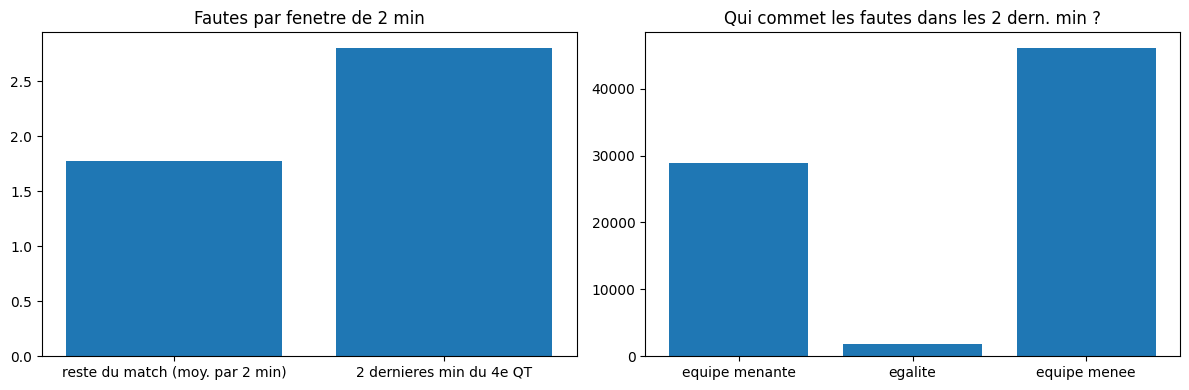

In [8]:
# fautes dans les 2 dernieres minutes du 4e QT vs reste du match
rs4 = rs.filter(F.col("period") == 4)
n4 = rs4.select("game_id").distinct().count()
fin = rs4.filter(F.col("rest") <= 120).withColumn(
    "marge_side", F.when(F.col("side") == "H", F.col("marge_dom")).otherwise(-F.col("marge_dom")))

fautes_fin = fin.filter(F.col("eventmsgtype") == 6)
n_fin = fautes_fin.count()
n_reste = rs.filter(~((F.col("period") == 4) & (F.col("rest") <= 120))) \
            .filter(F.col("eventmsgtype") == 6).count()
# le "reste du match" fait ~46 min -> ~23 fenetres de 2 min par match
taux = pd.DataFrame({
    "moment": ["reste du match (moy. par 2 min)", "2 dernieres min du 4e QT"],
    "fautes_par_match": [n_reste / n_matchs / 23, n_fin / n4]})

par_sit = (fautes_fin.groupBy(F.when(F.col("marge_side") < 0, "equipe menee")
                             .when(F.col("marge_side") > 0, "equipe menante")
                             .otherwise("egalite").alias("qui_faute"))
    .count().toPandas())
RESULTATS["fautes_fin"] = par_sit

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(taux.moment, taux.fautes_par_match); ax[0].set_title("Fautes par fenetre de 2 min")
ax[1].bar(par_sit.qui_faute, par_sit["count"])
ax[1].set_title("Qui commet les fautes dans les 2 dern. min ?")
plt.tight_layout(); plt.savefig("/work/resultats/04_fautes.png"); plt.show()

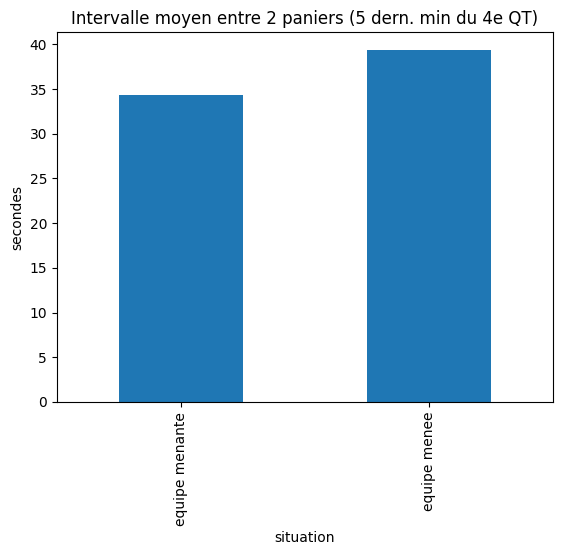

In [9]:
# gestion du chrono : l'equipe qui mene met-elle plus de temps a marquer ?
sc = rs.filter((F.col("pts") > 0) & (F.col("period") == 4) & (F.col("rest") <= 300))
w2 = Window.partitionBy("game_id", "side").orderBy("sec")
sc = (sc.withColumn("delta", F.col("sec") - F.lag("sec").over(w2))
        .withColumn("marge_side", F.when(F.col("side") == "H", F.col("marge_dom")).otherwise(-F.col("marge_dom"))))

rythme = (sc.filter(F.col("delta").isNotNull() & (F.col("delta") < 200))
    .groupBy(F.when(F.col("marge_side") > 0, "equipe menante").otherwise("equipe menee").alias("situation"))
    .agg(F.round(F.avg("delta"), 1).alias("sec_entre_pts"), F.count("*").alias("n"))
    .toPandas())
RESULTATS["ralentissement"] = rythme

rythme.plot(x="situation", y="sec_entre_pts", kind="bar", legend=False,
            title="Intervalle moyen entre 2 paniers (5 dern. min du 4e QT)")
plt.ylabel("secondes"); plt.savefig("/work/resultats/04_chrono.png"); plt.show()

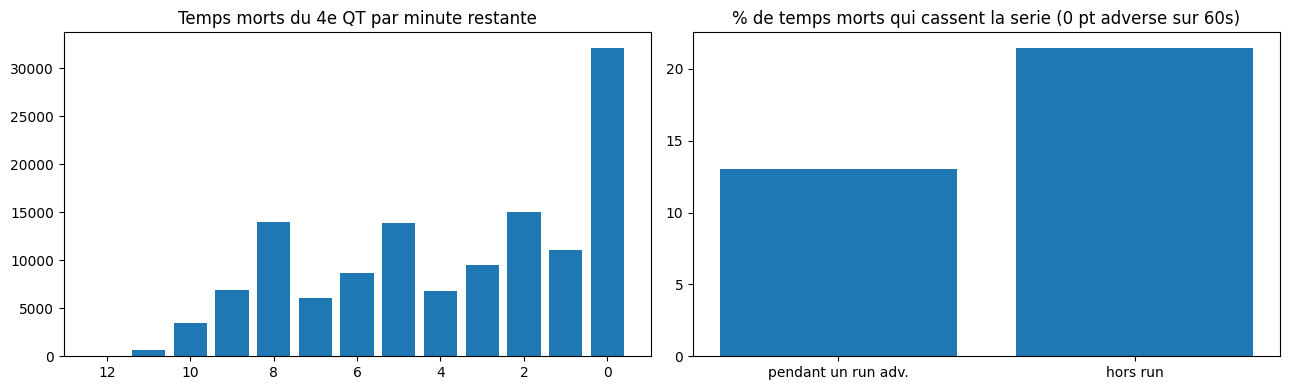

,run_adv,n,taux_casse
0,True,10099,0.130607
1,False,118214,0.214763


In [10]:
# temps morts : quand sont-ils poses ? cassent-ils un run adverse ?
to = rs.filter((F.col("eventmsgtype") == 9) & (F.col("period") == 4)) \
       .select("game_id", "eventnum", "sec", "rest", "side")
sc4 = rs.filter((F.col("pts") > 0) & (F.col("period") == 4)) \
        .select("game_id", "sec", "side", "pts")

dist_to = (to.withColumn("min_restante", F.floor(F.col("rest") / 60))
    .groupBy("min_restante").count().orderBy("min_restante").toPandas())
RESULTATS["timeouts_distrib"] = dist_to

# run adverse recent = l'adversaire a marque >=8 pts de plus que nous dans les 120s precedentes
avant = (to.alias("t").join(sc4.alias("s"),
            (F.col("t.game_id") == F.col("s.game_id"))
            & F.col("s.sec").between(F.col("t.sec") - 120, F.col("t.sec") - 1), "left")
    .groupBy(F.col("t.game_id"), F.col("t.eventnum"), F.col("t.sec"), F.col("t.side"))
    .agg(F.sum(F.when(F.col("s.side") != F.col("t.side"), F.col("s.pts"))).alias("adv"),
         F.sum(F.when(F.col("s.side") == F.col("t.side"), F.col("s.pts"))).alias("propres"))
    .fillna(0)
    .withColumn("run_adv", F.col("adv") - F.col("propres") >= 8))

# est-ce casse ? l'adversaire ne remarque pas dans les 60s suivantes
apres = (avant.alias("t").join(sc4.alias("s"),
            (F.col("t.game_id") == F.col("s.game_id"))
            & F.col("s.sec").between(F.col("t.sec"), F.col("t.sec") + 60)
            & (F.col("s.side") != F.col("t.side")), "left")
    .groupBy(F.col("t.game_id"), F.col("t.eventnum"), F.col("t.run_adv"))
    .agg(F.count(F.col("s.pts")).alias("pts_adv_60s"))
    .withColumn("casse", F.col("pts_adv_60s") == 0))

eff = (apres.groupBy("run_adv")
    .agg(F.count("*").alias("n"), F.mean(F.col("casse").cast("int")).alias("taux_casse"))
    .toPandas())
RESULTATS["timeouts_efficacite"] = eff

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(dist_to.min_restante, dist_to["count"]); ax[0].invert_xaxis()
ax[0].set_title("Temps morts du 4e QT par minute restante")
ax[1].bar(eff.run_adv.map({True: "pendant un run adv.", False: "hors run"}),
          eff.taux_casse * 100)
ax[1].set_title("% de temps morts qui cassent la serie (0 pt adverse sur 60s)")
plt.tight_layout(); plt.savefig("/work/resultats/04_timeouts.png"); plt.show()
eff

## 5. Les dynamiques du score

Fréquence et ampleur des séries (runs) et seuil à partir duquel un match est « plié ».

runs >= 8 pts : 75384  (2.90 par match, taille moyenne 9.6 pts)


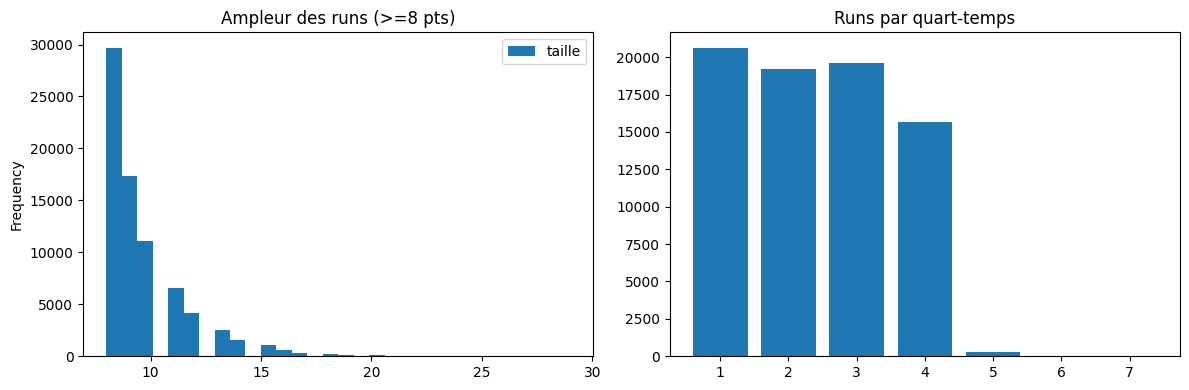

,game_id,gid,side,taille,period,debut
0,0020900292,7,A,29,1,495
1,0022000932,8,A,28,1,216
2,0020600610,2,H,27,1,60
3,0020201138,3,H,26,1,222
4,0020900215,9,A,26,1,417
5,0029601083,27,H,26,2,1435
6,0020300863,59,H,25,4,2182
7,0020601161,14,A,25,1,338
8,0020500853,40,H,25,3,1695
9,0021700963,7,H,25,1,412


In [11]:
# detection des runs : sequence de points marques par la meme equipe
sc_all = rs.filter(F.col("pts") > 0).select("game_id", "eventnum", "sec", "period", "side", "pts")
w3 = Window.partitionBy("game_id").orderBy("eventnum")
sc_all = (sc_all.withColumn("new", F.when(F.col("side") != F.lag("side").over(w3), 1).otherwise(0))
                .withColumn("gid", F.sum("new").over(w3)))

runs = (sc_all.groupBy("game_id", "gid")
    .agg(F.first("side").alias("side"), F.sum("pts").alias("taille"),
         F.min("period").alias("period"), F.min("sec").alias("debut"))
    .filter(F.col("taille") >= 8))

nb_runs = runs.count()
par_match = runs.groupBy("game_id").count().groupBy().avg("count").first()[0]
taille_moy = runs.groupBy().avg("taille").first()[0]
par_per = runs.groupBy("period").count().orderBy("period").toPandas()
top = runs.orderBy(F.desc("taille")).limit(10).toPandas()
RESULTATS["runs_resume"] = pd.DataFrame({"nb_runs": [nb_runs], "par_match": [par_match],
                                         "taille_moy": [taille_moy]})
RESULTATS["runs_par_periode"] = par_per
RESULTATS["top_runs"] = top

print(f"runs >= 8 pts : {nb_runs}  ({par_match:.2f} par match, taille moyenne {taille_moy:.1f} pts)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
runs.select("taille").toPandas().plot.hist(bins=30, ax=ax[0], title="Ampleur des runs (>=8 pts)")
ax[1].bar(par_per.period, par_per["count"]); ax[1].set_title("Runs par quart-temps")
plt.tight_layout(); plt.savefig("/work/resultats/05_runs.png"); plt.show()
top

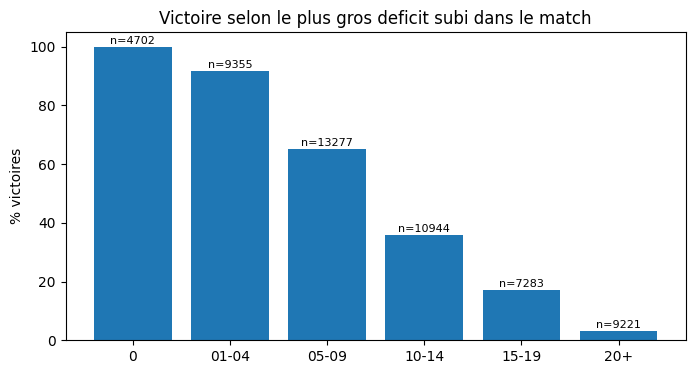

,tranche,win_pct,n
0,0,0.999149,4702
1,01-04,0.916622,9355
2,05-09,0.651126,13277
3,10-14,0.359832,10944
4,15-19,0.170946,7283
5,20+,0.031450,9221


In [12]:
# remontees : probabilite de gagner selon le plus gros deficit subi
marges = (rs.filter(F.col("side").isin("H", "A") & F.col("score_f").isNotNull())
    .withColumn("marge_side", F.when(F.col("side") == "H", F.col("marge_dom")).otherwise(-F.col("marge_dom")))
    .withColumn("gagne", F.when((F.col("side") == "H") & (F.col("wl_home") == "W"), True)
                         .when((F.col("side") == "A") & (F.col("wl_home") == "L"), True)
                         .otherwise(False)))

deficit = (marges.groupBy("game_id", "side")
    .agg((-F.min("marge_side")).alias("deficit_max"), F.first("gagne").alias("gagne"))
    .withColumn("tranche", F.when(F.col("deficit_max") <= 0, "0")
                           .when(F.col("deficit_max") <= 4, "01-04")
                           .when(F.col("deficit_max") <= 9, "05-09")
                           .when(F.col("deficit_max") <= 14, "10-14")
                           .when(F.col("deficit_max") <= 19, "15-19")
                           .otherwise("20+")))

taux = (deficit.groupBy("tranche").agg(F.mean(F.col("gagne").cast("int")).alias("win_pct"), F.count("*").alias("n"))
    .toPandas().sort_values("tranche").reset_index(drop=True))
RESULTATS["remontees"] = taux

plt.figure(figsize=(8, 4))
plt.bar(taux.tranche, taux.win_pct * 100)
plt.title("Victoire selon le plus gros deficit subi dans le match"); plt.ylabel("% victoires")
for i, r in taux.iterrows(): plt.text(i, r.win_pct * 100 + 1, f"n={r.n}", ha="center", fontsize=8)
plt.savefig("/work/resultats/05_remontees.png"); plt.show()
taux

## 6. Persistance — MongoDB

Les agrégats produits ci-dessus sont poussés dans la base `nba` (une collection par analyse) : c'est la couche *serving* de l'architecture, interrogable par un dashboard.

In [13]:
mongo = pymongo.MongoClient("mongodb://mongo:27017")["nba"]

for nom, df in RESULTATS.items():
    col = mongo[nom]
    col.drop()
    # to_json -> dicts python natifs (evite les types numpy non serialisables)
    col.insert_many(json.loads(df.to_json(orient="records")))
    print(f"{nom}: {col.count_documents({})} docs")

# relecture d'un echantillon pour verification
list(mongo.remontees.find({}, {"_id": 0}))[:3]

actions_minute: 48 docs
par_quart_temps: 4 docs
tirs_par_saison: 70 docs
tirs_par_quart: 4 docs
assist_decennie: 4 docs
assist_equipe: 30 docs
fautes_fin: 3 docs
ralentissement: 2 docs
timeouts_distrib: 13 docs
timeouts_efficacite: 2 docs
runs_resume: 1 docs
runs_par_periode: 7 docs
top_runs: 10 docs
remontees: 6 docs


[{'tranche': '0', 'win_pct': 0.9991492982, 'n': 4702},
 {'tranche': '01-04', 'win_pct': 0.9166221272, 'n': 9355},
 {'tranche': '05-09', 'win_pct': 0.6511260074, 'n': 13277}]

## 7. Limites & pistes

- **Couverture** : le play-by-play ne démarre qu'en 1996-97 ; les tendances long terme s'appuient sur `game.csv` (1946+).
- **Approximations** : les fautes « volontaires » sont détectées par contexte (fin de match serrée), pas par libellé ; un « run cassé » = 0 point adverse pendant 60 s.
- **Pistes** : prédire le vainqueur à la mi-temps (`line_score` + MLlib), rejouer un match en stream Kafka pour simuler l'ingestion temps réel, dashboard interactif (Mongo → Plotly Dash).